# Extração de Informações com LayoutLMv2

Notebook para carregar anotações da Roboflow (Food Chain ID), preparar os dados para o LayoutLMv2, treinar um modelo e gerar uma planilha com as informações extraídas nos demais relatórios da Food Chain ID.

## Pré-requisitos

- Dependências Python: `torch`, `transformers`, `datasets`, `pytesseract`, `pdf2image`, `opencv-python`, `Pillow`, `matplotlib`.
- Tesseract OCR instalado no sistema e acessível via `pytesseract.get_tesseract_version()`.
- Dataset exportado da Roboflow em formato YOLO OBB no caminho `data/processed_data/audit_reports_database/food-chain-id-yolov8-obb.zip`.
- Relatórios da Food Chain ID convertidos em imagens na pasta `data/processed_data/organized_audit_reports/Food Chain ID`.

In [1]:
from pathlib import Path
import json
import math
import zipfile
import torch
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
import pytesseract
import yaml
from datasets import Dataset, DatasetDict
from sklearn.model_selection import train_test_split
from transformers import (
    LayoutLMv2ForTokenClassification,
    Trainer,
    TrainingArguments,
)
from evaluate import load as load_metric


NOTEBOOK_CWD = Path.cwd().resolve()
if (NOTEBOOK_CWD / "data").exists():
    PROJECT_ROOT = NOTEBOOK_CWD
elif (NOTEBOOK_CWD.parent / "data").exists():
    PROJECT_ROOT = NOTEBOOK_CWD.parent
else:
    raise RuntimeError(f"Não encontrei a pasta 'data' ao redor de {NOTEBOOK_CWD}")

DATA_ROOT = PROJECT_ROOT / 'data'
ROBOFLOW_ZIP = DATA_ROOT / 'processed_data' / 'audit_reports_database' / 'food-chain-id-yolov8-obb.zip'
ROBOFLOW_DIR = DATA_ROOT / 'processed_data' / 'audit_reports_database' / 'food_chain_id_roboflow'
FOOD_CHAIN_DIR = DATA_ROOT / 'processed_data' / 'organized_audit_reports' / 'Food Chain ID'
DATASETS_DIR = PROJECT_ROOT / 'datasets'
DATASETS_DIR.mkdir(parents=True, exist_ok=True)

print('Usando projeto:', PROJECT_ROOT)
print('ZIP Roboflow:', ROBOFLOW_ZIP)
print('Anotações destino:', ROBOFLOW_DIR)
print('Relatórios Food Chain ID:', FOOD_CHAIN_DIR)
print('Pasta de trabalho:', DATASETS_DIR)

/home/cleyton/dev/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Usando projeto: /home/cleyton/dev/msc_thesis_naea_ufpa
ZIP Roboflow: /home/cleyton/dev/msc_thesis_naea_ufpa/data/processed_data/audit_reports_database/food-chain-id-yolov8-obb.zip
Anotações destino: /home/cleyton/dev/msc_thesis_naea_ufpa/data/processed_data/audit_reports_database/food_chain_id_roboflow
Relatórios Food Chain ID: /home/cleyton/dev/msc_thesis_naea_ufpa/data/processed_data/organized_audit_reports/Food Chain ID
Pasta de trabalho: /home/cleyton/dev/msc_thesis_naea_ufpa/datasets


In [2]:
if not ROBOFLOW_DIR.exists():
    with zipfile.ZipFile(ROBOFLOW_ZIP, 'r') as zf:
        zf.extractall(ROBOFLOW_DIR)
        print('Dataset extraído para', ROBOFLOW_DIR)
else:
    print('Dataset já extraído.')

print('Arquivos disponíveis:', sorted(p.name for p in ROBOFLOW_DIR.iterdir()))

Dataset já extraído.
Arquivos disponíveis: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'train']


In [3]:
with open(ROBOFLOW_DIR / 'data.yaml', 'r', encoding='utf-8') as stream:
    data_cfg = yaml.safe_load(stream)

class_names = {int(k): v for k, v in data_cfg['names'].items()}
print('Classes mapeadas:', len(class_names))
for idx, name in class_names.items():
    print(f"{idx:>2} -> {name}")

Classes mapeadas: 42
 0 -> 11
 1 -> 12
 2 -> 13
 3 -> 21
 4 -> 22
 5 -> 23
 6 -> 24
 7 -> 25
 8 -> 31
 9 -> 32
10 -> 33
11 -> 34
12 -> 41
13 -> 42
14 -> 43
15 -> 44
16 -> 45
17 -> 51
18 -> 510
19 -> 511
20 -> 52
21 -> 53
22 -> 54
23 -> 55
24 -> 56
25 -> 57
26 -> 58
27 -> 59
28 -> area
29 -> codigo_certificado
30 -> data_auditoria
31 -> data_prox_auditoria
32 -> decisao
33 -> endereco
34 -> localizacao_unidades
35 -> n_membros
36 -> nome_fazenda
37 -> producao
38 -> resumo_desempenho
39 -> tipo_avaliacao
40 -> tipo_estabelecimento
41 -> validade_certificado


## Utilitários de Geometria e OCR

In [4]:
def polygon_from_yolo_line(line: str, image_size):
    parts = line.strip().split()
    class_id = int(parts[0])
    coords = list(map(float, parts[1:]))
    w, h = image_size
    xs = coords[0::2]
    ys = coords[1::2]
    points = [(xs[i] * w, ys[i] * h) for i in range(len(xs))]
    min_x = min(p[0] for p in points)
    min_y = min(p[1] for p in points)
    max_x = max(p[0] for p in points)
    max_y = max(p[1] for p in points)
    bbox = [min_x, min_y, max_x, max_y]
    return class_id, points, bbox


def load_annotations(label_path: Path, image_size):
    if not label_path.exists():
        return []
    annotations = []
    with open(label_path, 'r', encoding='utf-8') as handle:
        for row in handle:
            class_id, polygon, bbox = polygon_from_yolo_line(row, image_size)
            annotations.append({'class_id': class_id, 'polygon': polygon, 'bbox': bbox})
    return annotations


def compute_iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b
    inter_x1 = max(ax1, bx1)
    inter_y1 = max(ay1, by1)
    inter_x2 = min(ax2, bx2)
    inter_y2 = min(ay2, by2)
    if inter_x2 <= inter_x1 or inter_y2 <= inter_y1:
        return 0.0
    inter_area = (inter_x2 - inter_x1) * (inter_y2 - inter_y1)
    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)
    union = area_a + area_b - inter_area
    if union <= 0:
        return 0.0
    return inter_area / union


def normalize_bbox(bbox, size):
    w, h = size
    return [
        int(1000 * max(0, min(bbox[0], w)) / w),
        int(1000 * max(0, min(bbox[1], h)) / h),
        int(1000 * max(0, min(bbox[2], w)) / w),
        int(1000 * max(0, min(bbox[3], h)) / h),
    ]


def run_ocr(image: Image.Image):
    data = pytesseract.image_to_data(image, output_type=pytesseract.Output.DICT)
    tokens = []
    for text, conf, left, top, width, height in zip(
        data['text'], data['conf'], data['left'], data['top'], data['width'], data['height']
    ):
        text = text.strip()
        try:
            conf_val = float(conf)
        except ValueError:
            conf_val = -1.0
        if not text or conf_val < 0:
            continue
        bbox = [left, top, left + width, top + height]
        tokens.append({'text': text, 'bbox': bbox, 'confidence': conf_val})
    return tokens

### Visualização rápida

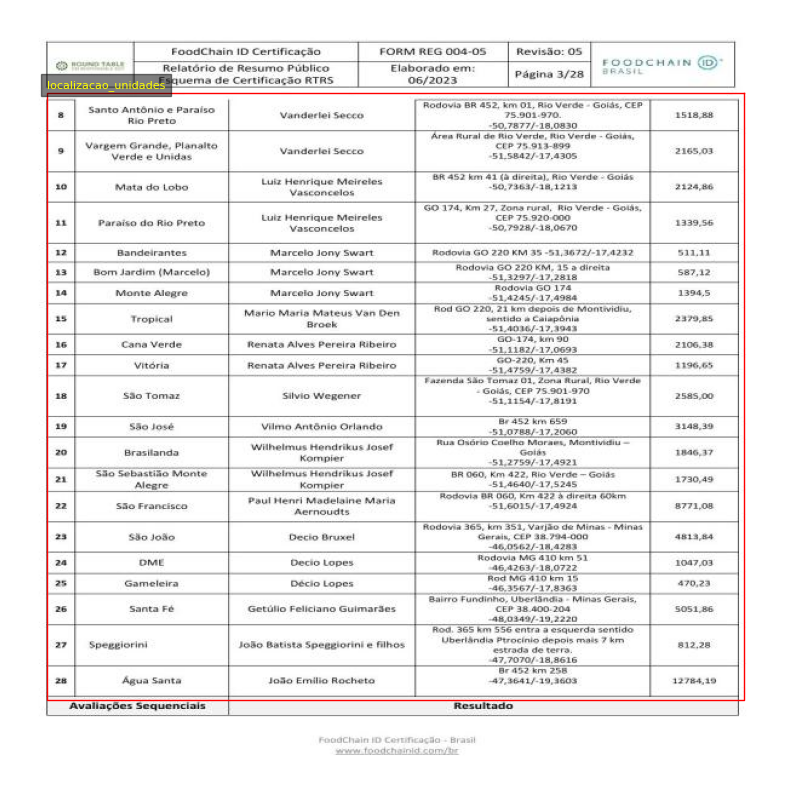

In [5]:
import random
import matplotlib.pyplot as plt

labels_dir = ROBOFLOW_DIR / 'train' / 'labels'
images_dir = ROBOFLOW_DIR / 'train' / 'images'
label_files = sorted(labels_dir.glob('*.txt'))

def plot_sample(label_file):
    image_file = images_dir / (label_file.stem + '.jpg')
    image = Image.open(image_file).convert('RGB')
    annotations = load_annotations(label_file, image.size)
    fig, ax = plt.subplots(figsize=(10, 12))
    ax.imshow(image)
    for ann in annotations:
        xs = [p[0] for p in ann['polygon']] + [ann['polygon'][0][0]]
        ys = [p[1] for p in ann['polygon']] + [ann['polygon'][0][1]]
        ax.plot(xs, ys, '-r', linewidth=1)
        min_x, min_y, max_x, max_y = ann['bbox']
        ax.text(min_x, min_y - 5, class_names[ann['class_id']], color='yellow', fontsize=8, bbox=dict(facecolor='black', alpha=0.5))
    ax.axis('off')
    plt.show()

plot_sample(random.choice(label_files))

## Conversão para o formato LayoutLMv2

In [6]:
def align_tokens_with_labels(image_path: Path, label_path: Path):
    image = Image.open(image_path).convert('RGB')
    tokens = run_ocr(image)
    annotations = load_annotations(label_path, image.size)

    words = [tok['text'] for tok in tokens]
    boxes = [tok['bbox'] for tok in tokens]
    labels = ['O'] * len(tokens)

    for ann in annotations:
        target_box = ann['bbox']
        target_label = class_names[ann['class_id']]
        candidate_indices = []
        for idx, token in enumerate(tokens):
            overlap = compute_iou(token['bbox'], target_box)
            if overlap >= 0.5:
                candidate_indices.append(idx)
        if candidate_indices:
            candidate_indices.sort()
            labels[candidate_indices[0]] = f'B-{target_label}'
            for idx in candidate_indices[1:]:
                labels[idx] = f'I-{target_label}'

    norm_boxes = [normalize_bbox(box, image.size) for box in boxes]
    return image, words, norm_boxes, labels


def create_examples(split='train'):
    images_dir = ROBOFLOW_DIR / split / 'images'
    labels_dir = ROBOFLOW_DIR / split / 'labels'
    examples = []
    for label_path in sorted(labels_dir.glob('*.txt')):
        image_path = images_dir / (label_path.stem + '.jpg')
        if not image_path.exists():
            continue
        image, words, boxes, labels = align_tokens_with_labels(image_path, label_path)
        examples.append({
            'image_path': image_path,
            'words': words,
            'boxes': boxes,
            'labels': labels,
        })
    return examples

train_examples = create_examples('train')
print('Exemplos de treino:', len(train_examples))
train_examples[0]['image_path'], len(train_examples[0]['words'])

Exemplos de treino: 142


(PosixPath('/home/cleyton/dev/msc_thesis_naea_ufpa/data/processed_data/audit_reports_database/food_chain_id_roboflow/train/images/page_10_jpg.rf.0d5e856d2835cca3df8ddbe79cbcfbf4.jpg'),
 100)

### Preparando o Processor do LayoutLMv2

In [7]:
from transformers import LayoutLMv2Processor

label_list = sorted(set(l for ex in train_examples for l in ex['labels'] if l != 'O'))
label_list = ['O'] + label_list
label_to_id = {label: idx for idx, label in enumerate(label_list)}
id_to_label = {idx: label for label, idx in label_to_id.items()}
print('Total de labels (BIO):', len(label_list))

processor = LayoutLMv2Processor.from_pretrained('microsoft/layoutlmv2-base-uncased', 
                                                apply_ocr=False)

lengths = {len(ex['words']) for ex in train_examples}
print('Faixa de tokens:', min(lengths), 'a', max(lengths))

Total de labels (BIO): 2
Faixa de tokens: 9 a 290


In [8]:
def encode_example(example):
    image = Image.open(example["image_path"]).convert("RGB")
    encoding = processor(
        image,
        example["words"],
        boxes=example["boxes"],
        word_labels=[label_to_id[label] for label in example["labels"]],
        padding="max_length",
        truncation=True,
        return_tensors="pt",
    )

    # garante que o tensor da imagem exista e seja float32
    if "pixel_values" in encoding:
        encoding["pixel_values"] = encoding["pixel_values"].float()
    elif "image" in encoding:  # caso que você já tinha
        encoding["pixel_values"] = encoding.pop("image").float()

    encoded = {key: val.squeeze(0) for key, val in encoding.items()}
    encoded["image_path"] = str(example["image_path"])
    return encoded


encoded_train = [encode_example(ex) for ex in train_examples]
print('Primeiro item codificado:')
for key, val in encoded_train[0].items():
    if key == 'image_path':
        print(' ', key, '->', val)
    else:
        print(' ', key, '->', val.shape)

Primeiro item codificado:
  input_ids -> torch.Size([512])
  token_type_ids -> torch.Size([512])
  attention_mask -> torch.Size([512])
  bbox -> torch.Size([512, 4])
  labels -> torch.Size([512])
  pixel_values -> torch.Size([3, 224, 224])
  image_path -> /home/cleyton/dev/msc_thesis_naea_ufpa/data/processed_data/audit_reports_database/food_chain_id_roboflow/train/images/page_10_jpg.rf.0d5e856d2835cca3df8ddbe79cbcfbf4.jpg


### Construindo Dataset do Hugging Face

In [9]:
from datasets import Dataset

train_dataset = Dataset.from_list([
    {
        'input_ids': item['input_ids'],
        'attention_mask': item['attention_mask'],
        'bbox': item['bbox'],
        'image': item['pixel_values'],
        'labels': item['labels'],
        'image_path': item['image_path'],
    }
    for item in encoded_train
])

print(train_dataset)

Dataset({
    features: ['input_ids', 'attention_mask', 'bbox', 'image', 'labels', 'image_path'],
    num_rows: 142
})


> Se desejar um conjunto de validação, separe uma fração de `train_examples` antes da codificação ou carregue pastas `valid/` fornecidas pela Roboflow.

## Treinamento com LayoutLMv2

In [10]:
# ------------------------------------------------------------------
# 1. Constrói Hugging Face Dataset a partir de encoded_train
# ------------------------------------------------------------------
print(f"Total de exemplos anotados: {len(encoded_train)}")

train_items, valid_items = train_test_split(
    encoded_train,
    test_size=0.1,
    random_state=42,
    shuffle=True,
)

train_ds = Dataset.from_list([
    {
        "input_ids": item["input_ids"],
        "attention_mask": item["attention_mask"],
        "bbox": item["bbox"],
        "pixel_values": item["pixel_values"],
        "labels": item["labels"],
    }
    for item in train_items
])
valid_ds = Dataset.from_list([
    {
        "input_ids": item["input_ids"],
        "attention_mask": item["attention_mask"],
        "bbox": item["bbox"],
        "pixel_values": item["pixel_values"],
        "labels": item["labels"],
    }
    for item in valid_items
])

hf_dataset = DatasetDict({"train": train_ds, "validation": valid_ds})
hf_dataset

Total de exemplos anotados: 142


DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'bbox', 'pixel_values', 'labels'],
        num_rows: 127
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'bbox', 'pixel_values', 'labels'],
        num_rows: 15
    })
})

In [11]:
# ------------------------------------------------------------------
# 2. Carrega LayoutLMv2 com o mesmo esquema de rótulos
# ------------------------------------------------------------------
from transformers import LayoutLMv3ForTokenClassification, Trainer, TrainingArguments

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = LayoutLMv3ForTokenClassification.from_pretrained(
    "microsoft/layoutlmv3-base",
    num_labels=len(label_list),
    id2label=id_to_label,
    label2id=label_to_id,
)

model = model.to(device)


Some weights of LayoutLMv3ForTokenClassification were not initialized from the model checkpoint at microsoft/layoutlmv3-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [12]:
# ------------------------------------------------------------------
# 3. Métrica auxiliar (F1 token-level)
# ------------------------------------------------------------------
seqeval = load_metric("seqeval")

def align_predictions(predictions, label_ids):
    preds = np.argmax(predictions, axis=2)
    batch_size, seq_len = preds.shape
    preds_list, out_label_list = [], []

    for batch_idx in range(batch_size):
        example_preds = []
        example_labels = []
        for seq_idx in range(seq_len):
            label_id = label_ids[batch_idx, seq_idx]
            if label_id == -100:
                continue
            example_preds.append(id_to_label[preds[batch_idx, seq_idx]])
            example_labels.append(id_to_label[label_id])
        preds_list.append(example_preds)
        out_label_list.append(example_labels)
    return preds_list, out_label_list

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds, refs = align_predictions(logits, labels)
    results = seqeval.compute(predictions=preds, references=refs)
    return {
        "precision": results["overall_precision"],
        "recall": results["overall_recall"],
        "f1": results["overall_f1"],
        "accuracy": results["overall_accuracy"],
    }


In [ ]:
# ------------------------------------------------------------------
# 4. Argumentos de treinamento
# ------------------------------------------------------------------
OUTPUT_DIR = DATASETS_DIR / "layoutlmv2-foodchain"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR),
    do_train=True,
    do_eval=True,          # apenas habilita o passo de avaliação
    save_steps=500,
    logging_steps=100,
    learning_rate=5e-5,
    weight_decay=0.01,
    num_train_epochs=10,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    fp16=torch.cuda.is_available(),
)


: 

In [ ]:
# ------------------------------------------------------------------
# 5. Treinador e fine-tuning
# ------------------------------------------------------------------
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=hf_dataset["train"],
    eval_dataset=hf_dataset["validation"],
    tokenizer=processor.tokenizer,
    compute_metrics=compute_metrics,
)

train_result = trainer.train()
trainer.save_model(str(OUTPUT_DIR / "checkpoint-last"))
processor.save_pretrained(str(OUTPUT_DIR / "processor"))

train_result

/tmp/ipykernel_64459/3060660410.py:4: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': None, 'bos_token_id': None, 'pad_token_id': 0}.
/home/cleyton/dev/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/home/cleyton/dev/.venv/lib/python3.12/site-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(


Step,Training Loss
100,0.006600


In [ ]:
# ------------------------------------------------------------------
# 6. Histórico de métricas
# ------------------------------------------------------------------
metrics = trainer.evaluate()
metrics


In [ ]:
# (Opcional) Históricos completos para inspeção manual
trainer.state.log_history[:5]


> O treinamento pode ser demorado. Ajuste `num_train_epochs`, `per_device_train_batch_size` e considere usar GPU.

## Geração de Tabela a partir dos Relatórios

In [ ]:
from collections import defaultdict
import torch


def prepare_report_page(image_path: Path):
    image = Image.open(image_path).convert("RGB")
    tokens = run_ocr(image)
    words = [tok["text"] for tok in tokens]
    boxes = [normalize_bbox(tok["bbox"], image.size) for tok in tokens]

    encoding = processor(
        image,
        words,
        boxes=boxes,
        return_tensors="pt",
        padding="max_length",
        truncation=True,
    )

    if "pixel_values" in encoding:
        encoding["pixel_values"] = encoding["pixel_values"].float()
    elif "image" in encoding:
        encoding["pixel_values"] = encoding.pop("image").float()

    encoding["words"] = words
    encoding["raw_boxes"] = boxes
    encoding["image_path"] = str(image_path)
    return encoding

def predict_tokens(encoding):
    with torch.no_grad():
        outputs = model(
            input_ids=encoding['input_ids'],
            attention_mask=encoding['attention_mask'],
            bbox=encoding['bbox'],
            pixel_values=encoding['pixel_values']
        )
        probs = outputs.logits.softmax(dim=-1)
        scores, preds = probs.max(dim=-1)
    return preds.squeeze(0).tolist(), scores.squeeze(0).tolist()


def aggregate_report(report_dir: Path, confidence_threshold=0.99):
    columns = defaultdict(list)
    pages = sorted(report_dir.glob('page_*.jpg'))
    for page in pages:
        encoding = prepare_report_page(page)
        preds, scores = predict_tokens(encoding)
        words = encoding['words']
        for token, label_id, score in zip(words, preds, scores):
            label = id_to_label.get(label_id, 'O')
            if label == 'O':
                continue
            if score < confidence_threshold:
                continue
            label_name = label.replace('B-', '').replace('I-', '')
            columns[label_name].append(token)
    aggregated = {col: ' '.join(values) if values else '' for col, values in columns.items()}
    aggregated['report_id'] = report_dir.name
    return aggregated


def build_foodchain_table(root_dir=FOOD_CHAIN_DIR, confidence_threshold=0.99):
    records = []
    for report_dir in sorted(root_dir.iterdir()):
        if not report_dir.is_dir():
            continue
        record = aggregate_report(report_dir, confidence_threshold=confidence_threshold)
        records.append(record)
    df = pd.DataFrame(records).set_index('report_id')
    ordered_cols = [str(value) for value in class_names.values()]
    ordered_cols.sort()
    df = df.reindex(columns=ordered_cols, fill_value='')

    return df


In [ ]:
foodchain_df = build_foodchain_table(confidence_threshold=0.70)
foodchain_df.to_csv(DATASETS_DIR / 'foodchain_extracted.csv')
foodchain_df.head()

/home/cleyton/dev/.venv/lib/python3.12/site-packages/transformers/modeling_utils.py:1625: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/home/cleyton/dev/.venv/lib/python3.12/site-packages/transformers/modeling_utils.py:1625: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/home/cleyton/dev/.venv/lib/python3.12/site-packages/transformers/modeling_utils.py:1625: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/home/cleyton/dev/.venv/lib/python3.12/site-packages/transformers/modeling_utils.py:1625: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/home/cleyton/dev/.venv/lib/python3.12/site-packages/transformers/modeling_utils.py:1625: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.w

KeyboardInterrupt: 

In [ ]:
foodchain_df

,11,12,13,21,22,23,24,25,31,32,...,decisao,endereco,localizacao_unidades,n_membros,nome_fazenda,producao,resumo_desempenho,tipo_avaliacao,tipo_estabelecimento,validade_certificado
report_id,,,,,,,,,,,,,,,,,,,,,
audit_report_rtrs10,,,,,,,,,,,...,,,,,,,,,,
audit_report_rtrs100,,,,,,,,,,,...,,,,,,,,,,
audit_report_rtrs110,,,,,,,,,,,...,,,,,,,,,,
audit_report_rtrs111,,,,,,,,,,,...,,,,,,,,,,
audit_report_rtrs112,,,,,,,,,,,...,,,,,,,,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
audit_report_rtrs9,,,,,,,,,,,...,,,,,,,,,,
audit_report_rtrs90,,,,,,,,,,,...,,,,,,,,,,
audit_report_rtrs91,,,,,,,,,,,...,,,,,,,,,,


## Próximos Passos

- Ajustar o limiar de confiança e regras de agregação conforme análise dos resultados.
- Tratar duplicatas e normalizar valores (datas, códigos, áreas) na base resultante.
- Expandir o pipeline para outras certificadoras treinando modelos específicos ou realizando fine-tuning incremental.